In [11]:
import numpy as np
from manifold3d import Manifold, Mesh
import k3d
import trimesh
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt

In [2]:
def create_box_manifold(width, length, height, z_offset=0.0):
    """Generates a Manifold object for a solid rectangular box."""
    # 1. Define 8 vertices for a straight box
    vertices = np.array([
        # Bottom 4 vertices (z = z_offset)
        [-width / 2, -length / 2, z_offset],  # 0: Bottom-left
        [ width / 2, -length / 2, z_offset],  # 1: Bottom-right
        [ width / 2,  length / 2, z_offset],  # 2: Top-right
        [-width / 2,  length / 2, z_offset],  # 3: Top-left
        
        # Top 4 vertices (z = height + z_offset)
        [-width / 2, -length / 2, height + z_offset],  # 4: Top-left (Upper)
        [ width / 2, -length / 2, height + z_offset],  # 5: Top-right (Upper)
        [ width / 2,  length / 2, height + z_offset],  # 6: Bottom-right (Upper)
        [-width / 2,  length / 2, height + z_offset],  # 7: Bottom-left (Upper)
    ], dtype=np.float32)

    # 2. Define 12 triangular faces
    faces = np.array([
        [0, 2, 1], [0, 3, 2],  # Bottom
        [4, 5, 6], [4, 6, 7],  # Top
        [0, 1, 5], [0, 5, 4],  # Front
        [1, 2, 6], [1, 6, 5],  # Right
        [2, 3, 7], [2, 7, 6],  # Back
        [3, 0, 4], [3, 4, 7],  # Left
    ], dtype=np.int32)

    # 3. Construct the native Manifold object
    mesh = Mesh(vert_properties=vertices, tri_verts=faces)
    return Manifold(mesh)

def create_frustum_manifold(bottom_w, bottom_l, top_w, top_l, height, z_offset=0.0):
    """
    Generates a Manifold object for a 4-sided frustum.
    bottom_w, bottom_l: bottom width and length
    top_w, top_l: top length and width
    """
    # 1. Define 8 vertices for the frustum
    vertices = np.array([
        [-bottom_w / 2, -bottom_l / 2, z_offset],  # 0: Bottom-left
        [ bottom_w / 2, -bottom_l / 2, z_offset],  # 1: Bottom-right
        [ bottom_w / 2,  bottom_l / 2, z_offset],  # 2: Top-right
        [-bottom_w / 2,  bottom_l / 2, z_offset],  # 3: Top-left
        
        [-top_w / 2, -top_l / 2, height + z_offset],  # 4: Top-left (Upper)
        [ top_w / 2, -top_l / 2, height + z_offset],  # 5: Top-right (Upper)
        [ top_w / 2,  top_l / 2, height + z_offset],  # 6: Bottom-right (Upper)
        [-top_w / 2,  top_l / 2, height + z_offset],  # 7: Bottom-left (Upper)
    ], dtype=np.float32)

    # 2. Define 12 triangular faces for the frustum
    faces = np.array([
        [0, 2, 1], [0, 3, 2],  # bottom face (facing -z)
        [4, 5, 6], [4, 6, 7],  # top face (facing +z)
        [0, 1, 5], [0, 5, 4],  # front face (facing -y)
        [1, 2, 6], [1, 6, 5],  # right face (facing +x)
        [2, 3, 7], [2, 7, 6],  # back face (facing +y)
        [3, 0, 4], [3, 4, 7],  # left face (facing -x)
    ], dtype=np.int32)

    # 3. Construct the native Manifold object
    mesh = Mesh(vert_properties=vertices, tri_verts=faces)
    return Manifold(mesh)

def create_hollow_box(in_w, in_l, h, thickness, z_offset=0.0):
    """
    Creates a hollow rectangular box (tube) defined by its INNER dimensions.
    Top and bottom are fully open.

    in_w, in_l: inner width and length
    h: total height of the box
    thickness: wall thickness
    """
    # 1. Calculate outer dimensions directly (just add thickness to both sides)
    out_w = in_w + (2 * thickness)
    out_l = in_l + (2 * thickness)
    out_h = h

    # 2. Calculate inner cutting dimensions
    # Extend the inner box by 1 unit on top and bottom to ensure a clean Boolean cut
    z_extend = 1.0
    ext_in_h = h + (2 * z_extend)

    # 3. Build Outer and Inner Manifolds
    outer = create_box_manifold(out_w, out_l, out_h, z_offset=z_offset)

    # Push the inner box down by z_extend so it cuts completely through the floor and ceiling
    inner = create_box_manifold(in_w, in_l, ext_in_h, z_offset=z_offset - z_extend)

    # 4. Native Boolean Difference
    hollow_box = outer - inner

    return hollow_box


def create_collimator_manifold(
    l_top, h_nozzle, w_pinhole, w_wall, l_bottom_inner, l_bottom_outer, h_body, h_box
):
    """
    Creates a frustum collimator with specified dimensions.

    l_top: length of the top opening (pinhole)
    h_nozzle: height of the nozzle section
    w_pinhole: width of the pinhole
    w_wall: wall thickness
    l_bottom_inner: inner length of the bottom opening
    l_bottom_outer: outer length of the bottom opening
    h_body: height of the body section
    h_box: height of the box section
    """

    # Create the main frustum body
    frustum_manifold_a = create_frustum_manifold(
        l_bottom_outer, l_bottom_outer, l_top, l_top, h_nozzle + h_body, z_offset=h_box
    )
    frustum_manifold_b = create_frustum_manifold(
        w_pinhole, w_pinhole, l_top, l_top, h_nozzle, z_offset=h_body + h_box
    )
    frustum_manifold_c = create_frustum_manifold(
        l_bottom_inner, l_bottom_inner, w_pinhole, w_pinhole, h_body, z_offset=h_box
    )
    base_box_manifold = create_hollow_box(
        l_bottom_outer - 2 * w_wall, l_bottom_outer - 2 * w_wall, h_box, w_wall
    )
    # basde_box_manifold = base_box_manifold.translate([0, 0, h_nozzle + h_body])
    # collimator_manifold = frustum_manifold_a - frustum_manifold_b - frustum_manifold_c + base_box_manifold
    collimator_manifold = (
        frustum_manifold_a - frustum_manifold_b - frustum_manifold_c + base_box_manifold
    )
    return collimator_manifold


collimator_manifold = create_collimator_manifold(
    l_top=5.04,
    h_nozzle=10.74,
    w_pinhole=0.556,
    w_wall=2.03,
    l_bottom_inner=50.0,
    l_bottom_outer=56.064,
    h_body=25.0,
    h_box=23.5,
)

In [3]:
h_body = 25.0
h_box = 23.5

collimator_manifold = create_collimator_manifold(
    l_top=10.74,
    h_nozzle=5.04,
    w_pinhole=0.556,
    w_wall=2.03,
    l_bottom_inner=50.0,
    l_bottom_outer=56.064,
    h_body=h_body,
    h_box=h_box,
)
collimator_manifold = collimator_manifold.translate([0.0, 0.0, -(h_body+h_box)])  # Shift down by sum of body and box heights in Z
collimator_manifold = collimator_manifold.rotate([0.0, -90.0, 0.0])  # Rotate around X-axis by -90 degrees
collimator_mesh_data = collimator_manifold.to_mesh()
collimator_vertices = (
   collimator_mesh_data.vert_properties[:, :3].astype(np.float32)
)
collimator_indices = collimator_mesh_data.tri_verts.astype(np.uint32)



In [ ]:
import matplotlib.pyplot as plt

# Ensure you have the Trimesh object created from your clean vertices
collimator_trimesh = trimesh.Trimesh(
    vertices=collimator_vertices, faces=collimator_indices
)
stl_dir = Path(
    "/Users/fanghan/Work/RPIL/rpil-research-note/brain-spect-geometry/python/stl"
)
stl_filename = "BrainSPECT_Module.008.25mm_at_0.556.STL"
stl_path = stl_dir / stl_filename


In [24]:


def plot_2d_projection(
    collimator, stl, pinhole_width, origin, normal, x_idx, y_idx, x_label, y_label, title, filename
):
    """
    Unified function to slice meshes and plot a 2D projection in a new window.
    """
    fig, ax = plt.subplots(figsize=(8, 8))

    # 1. Calculate the mathematical slice (cross-section)
    c_slice = collimator.section(plane_origin=origin, plane_normal=normal)
    s_slice = stl.section(plane_origin=origin, plane_normal=normal)

    # 2. Internal helper to draw the line segments
    def draw_slice(mesh_slice, color, style="-", label="", alpha=1.0):
        if mesh_slice is not None:
            for i, segment in enumerate(mesh_slice.discrete):
                # We use x_idx and y_idx to pick the correct 3D coordinates for the 2D plot
                ax.plot(
                    segment[:, x_idx],
                    segment[:, y_idx],
                    color=color,
                    ls=style,
                    linewidth=2,
                    label=label if i == 0 else "",
                    alpha=alpha,
                )

    # 3. Draw both slices
    draw_slice(c_slice, "blue", "-", "Constructed by Boolean Operations", alpha=0.8)
    draw_slice(s_slice, "orange", "--", "Imported STL", alpha=0.8)

    # 4. Formatting
    ax.set_aspect("equal")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.7)
    ax.legend(loc="upper left", fontsize=10)

    # 5 Add Pinhole Width Annotation
    pinhole_width = pinhole_width  # Example value, replace with actual if needed
    ax.annotate(
        f"Pinhole Width: {pinhole_width:.3f} mm",
        xy=(0.6, 0.5),  # Position in axes fraction
        xycoords="axes fraction",
        fontsize=10,
        color="black",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.5),
    )

    # 6. Save and display
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    print(f"Saved: '{filename}'")

    # plt.show() pauses the script and opens the interactive window.
    # Close the window to generate the next projection.
    # plt.show()


In [7]:
variable_data = [
    [0.556, 5.04, 10.74, 149.61],
    [0.750, 5.03, 10.95, 150.01],
    [0.797, 5.02, 11.00, 150.10],
    [1.000, 5.01, 11.23, 150.53],
    [1.215, 5.00, 11.46, 150.98],
    [1.500, 4.99, 11.78, 151.58],
    [2.000, 4.96, 12.33, 152.66],
    [2.007, 4.96, 12.33, 152.67],
    [2.500, 4.94, 12.87, 153.77],
    [3.000, 4.92, 13.42, 154.90],
]

constant_data = [2.03, 50.0, 56.064, 25.0, 23.5]

# Combine rows seamlessly (including the empty first column)
all_rows = [var_row + constant_data for var_row in variable_data]

# 2. Define the final LaTeX headers directly
headers = [
    "Pinhole Width (mm)",
    "Nozzle Height (mm)",
    "Top Length (mm)",
    "Bottom Length (mm)",
    "Wall Thickness (mm)",
    "Bottom Inner Length (mm)",
    "Bottom Outer Length (mm)",
    "Body Height (mm)",
    "Box Height (mm)",
]

pl_df = pl.DataFrame(all_rows, schema=headers, orient="row")
print(pl_df.filter(pl.col("Pinhole Width (mm)") == 3.000).row(0))

(3.0, 4.92, 13.42, 154.9, 2.03, 50.0, 56.064, 25.0, 23.5)


Saved: '../../figs/collimator_pinhole_w_3.000_x_projection.png'
Saved: '../../figs/collimator_pinhole_w_3.000_y_projection.png'
Saved: '../../figs/collimator_pinhole_w_3.000_z_projection.png'


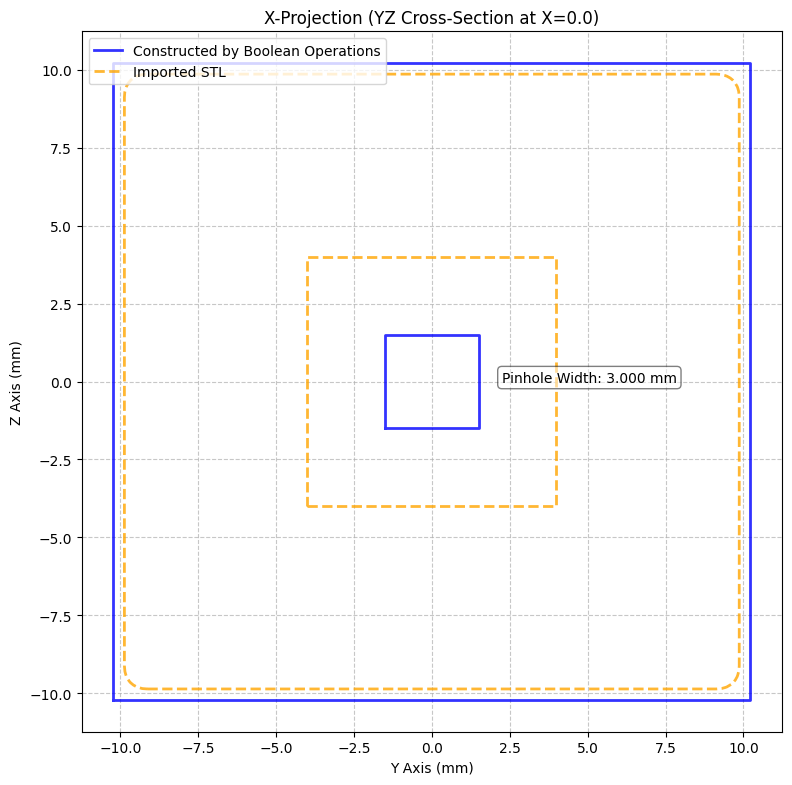

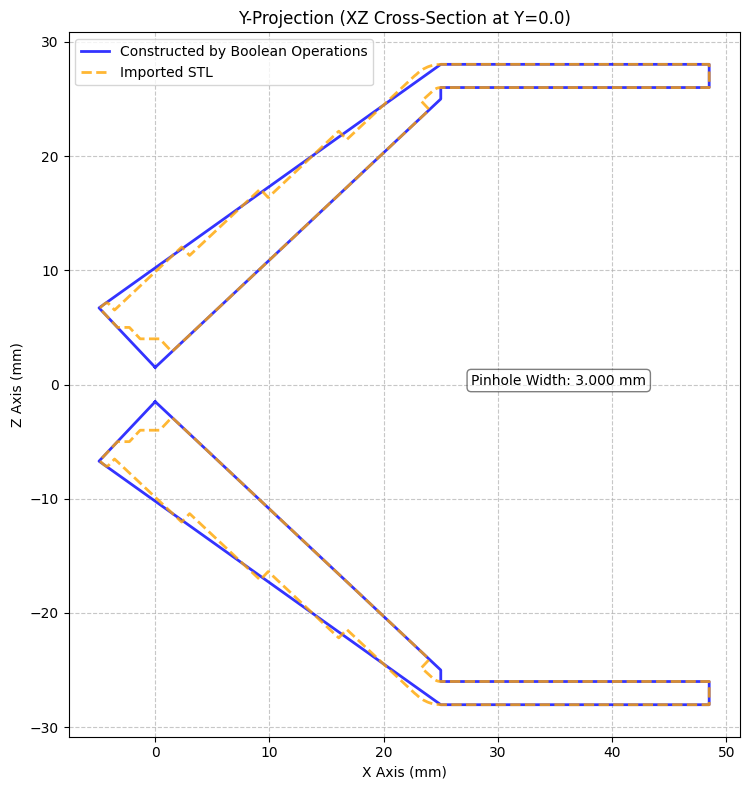

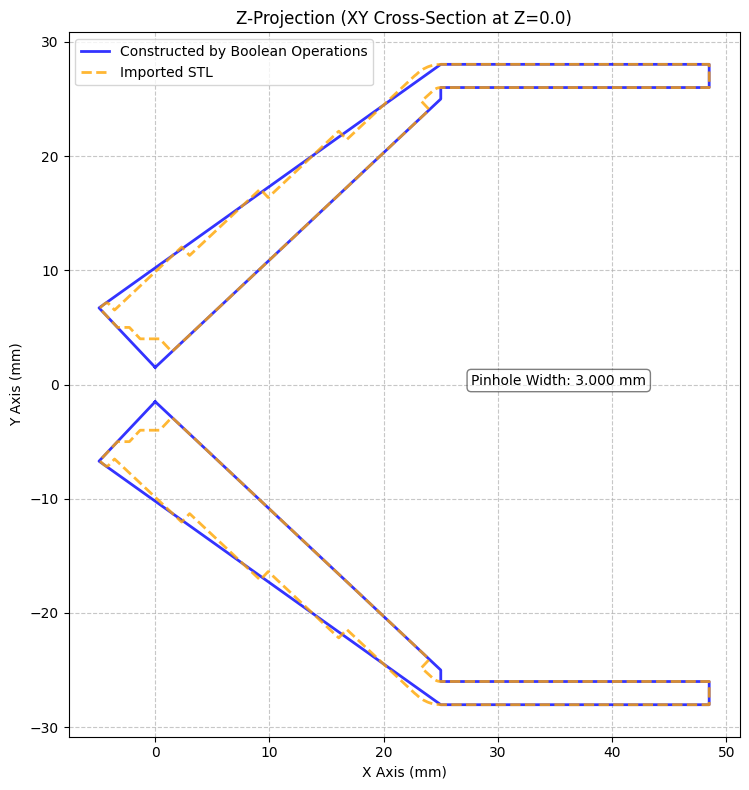

In [25]:
pinhole_width = 3.000
settings = pl_df.filter(pl.col("Pinhole Width (mm)") == 3.000).row(0)
collimator_manifold = create_collimator_manifold(
    l_top=settings[2],
    h_nozzle=settings[1],
    w_pinhole=pinhole_width,
    w_wall=settings[4],
    l_bottom_inner=settings[5],
    l_bottom_outer=settings[6],
    h_body=settings[7],
    h_box=settings[8]
)
collimator_manifold = collimator_manifold.translate([0.0, 0.0, -(settings[7] + settings[8])])  # Shift down by sum of body and box heights in Z
collimator_manifold = collimator_manifold.rotate([0.0, -90.0, 0.0])  # Rotate around X-axis by -90 degrees
collimator_mesh_data = collimator_manifold.to_mesh()
collimator_vertices = (
   collimator_mesh_data.vert_properties[:, :3].astype(np.float32)
)
collimator_indices = collimator_mesh_data.tri_verts.astype(np.uint32)

collimator_trimesh = trimesh.Trimesh(
    vertices=collimator_vertices, faces=collimator_indices
)
stl_dir = Path(
    "/Users/fanghan/Work/RPIL/rpil-research-note/brain-spect-geometry/python/stl"
)
stl_filename = "BrainSPECT_Module.008.25mm_at_0.556.STL"
stl_path = stl_dir / stl_filename

output_dir_str = "../../figs" 
# ==========================================
# Generate All 3 Projections
# ==========================================
stl_mesh = trimesh.load(stl_path, force="mesh")
stl_mesh.apply_translation([-149.61, 0, 0])
# 1. X-Projection (Slice YZ Plane, Look down X)
x_height = 0.0 # Slice through the middle of the 25mm base box
y_height = 0.0 # Slice through the middle of the 25mm base box
z_height = 0.0 # Slice through the middle of the 25mm base box
plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    pinhole_width=pinhole_width,
    origin=[x_height, 0, 0], normal=[1, 0, 0],     # Cut along X=0
    x_idx=1, y_idx=2,                       # Plot Y vs Z
    x_label='Y Axis (mm)', y_label='Z Axis (mm)',
    title=f'X-Projection (YZ Cross-Section at X={x_height})',
    filename=f'{output_dir_str}/collimator_pinhole_w_{pinhole_width:.3f}_x_projection.png'
)

# 2. Y-Projection (Slice XZ Plane, Look down Y)

plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    pinhole_width=pinhole_width,
    origin=[0, y_height, 0], normal=[0, 1, 0],     # Cut along Y=0
    x_idx=0, y_idx=2,                       # Plot X vs Z
    x_label='X Axis (mm)', y_label='Z Axis (mm)',
    title=f'Y-Projection (XZ Cross-Section at Y={y_height})',
    filename=f'{output_dir_str}/collimator_pinhole_w_{pinhole_width:.3f}_y_projection.png'
)

# 3. Z-Projection (Slice XY Plane, Look down Z)

plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    pinhole_width=pinhole_width,
    origin=[0, 0, z_height], normal=[0, 0, 1], # Cut along Z=12.5
    x_idx=0, y_idx=1,                          # Plot X vs Y
    x_label='X Axis (mm)', y_label='Y Axis (mm)',
    title=f'Z-Projection (XY Cross-Section at Z={z_height})',
    filename=f'{output_dir_str}/collimator_pinhole_w_{pinhole_width:.3f}_z_projection.png'
)